# Bifurcación de canales — Fase I-bis: líneas de corriente y equipotenciales (Formulación I)
## Trabajo 01 · Estructura N.º 8 · Flujo en superficie libre — UNSCH, Unidad de Posgrado

**Por qué este cuaderno.** En la presentación del avance, el docente sugirió añadir las **líneas de corriente y de potencial** del modelo ideal de Milne-Thomson (§10·8). Las Fases I y II resolvieron solo el *reparto de caudales* ($u_1$, $u_2$); este cuaderno recupera de esa misma solución el **campo de flujo completo** dentro de la bifurcación: la red de flujo (*flow net*) formada por las líneas $\psi=$ cte y $\varphi=$ cte, y la velocidad en cada punto.

**Base teórica.** El potencial complejo $w(z)=\varphi+i\psi$ y el mapeo conforme del canal al semiplano superior mediante el teorema de Schwarz–Christoffel (Milne-Thomson, §10·8; Batchelor, *An Introduction to Fluid Dynamics*, §6.5, pp. 409–423; Gurevich, *Theory of Jets in an Ideal Fluid*, cap. I, §1).

**Qué se entrega**
1. La red de flujo para el caso de la Fase I y para **la geometría exacta del modelo 2D** (HEC-RAS), para poder superponerlas.
2. Siete pruebas de verificación documentadas, incluida una **prueba con control negativo** que demuestra que detecta una solución errónea.
3. Un archivo CSV con las líneas del caso 2D en las coordenadas del generador (locales y UTM ficticias).

**Alcance y límites (declarados desde el inicio).** Es el modelo ideal: plano, irrotacional, sin fricción, sin separación y con tapa rígida ($Fr\to 0$). La red de flujo **no es una predicción del flujo real**: es lo que el modelo ideal dice, y sirve para ver *dónde* deja de ser creíble (esquina $E$) y para contrastarlo con el 2D en la Fase IV.

## 1. Teoría mínima: de $\zeta$ al plano físico

Con el flujo plano e irrotacional, la velocidad compleja es $dw/dz=u-iv=q\,e^{-i\theta}$. Milne-Thomson mapea el interior del canal al **semiplano superior** de la variable auxiliar $\zeta$ mediante

$$
\zeta=-\left(\frac{dw/dz}{U}\right)^{\pi/\alpha}\quad\Longleftrightarrow\quad \frac{dw}{dz}=U\,(-\zeta)^{\alpha/\pi}\qquad(1)
$$

y los puntos de la frontera quedan en el eje real: $A_\infty$ (entrada) en $\zeta=-1$, $B_\infty$ (canal principal aguas abajo) en $\zeta=-b$, $C$ (estancamiento) en $\zeta=0$, $D_\infty$ (ramal) en $\zeta=c$ y $E$ en $\zeta=\infty$, con $b=u_1^{\pi/\alpha}$ y $c=u_2^{\pi/\alpha}$.

**Potencial complejo** (fuentes y sumideros en $A_\infty$, $B_\infty$, $D_\infty$), con $Q_0=Uh$, $Q_1=U_1h_1$, $Q_2=U_2h_2$:

$$
w(\zeta)=\frac{Q_0}{\pi}\log\frac{\zeta+1}{\zeta-c}-\frac{Q_1}{\pi}\log\frac{\zeta+b}{\zeta-c}\qquad(2)
$$

**Geometría.** Como $dz=\dfrac{dw/d\zeta}{dw/dz}\,d\zeta$,

$$
\frac{dz}{d\zeta}=\frac{w'(\zeta)}{U\,(-\zeta)^{\alpha/\pi}}\qquad(3)
$$

y $z(\zeta)$ se obtiene integrando (3) desde $\zeta=0$ (el punto $C$, que se toma como origen $z=0$). No existe forma cerrada para $\alpha$ cualquiera, por lo que se integra numéricamente con cuadratura adaptativa.

**Cómo se trazan las líneas (sin malla).** A lo largo de una línea de corriente $d\psi=0$, de modo que $dw=d\varphi$ real; a lo largo de una equipotencial $dw=i\,d\psi$. Por la regla de la cadena, en el plano $\zeta$:

$$
\text{corriente: }\ \frac{d\zeta}{d\varphi}=\frac{1}{w'(\zeta)},\quad \frac{dz}{d\varphi}=\frac{1}{dw/dz};\qquad
\text{equipotencial: }\ \frac{d\zeta}{d\psi}=\frac{i}{w'(\zeta)},\quad \frac{dz}{d\psi}=\frac{i}{dw/dz}.\qquad(4)
$$

Son EDO regulares en el interior. Se integran con un método Runge–Kutta de orden 8 (DOP853, `rtol`$=10^{-11}$), con valores iniciales sobre las paredes (donde $\zeta$ es real y $\varphi$ es monótona) y sobre un rayo vertical en $\zeta$ para las líneas de corriente. Un mallado triangular del semiplano falla porque las escalas van de $10^{-8}$ a $10^{5}$; las EDO no tienen ese problema.

**Valores de $\psi$ en las paredes** (se deducen de (2)): $\psi=0$ en la pared aguas arriba y en la pared exterior del ramal; $\psi=-Q_0$ en la pared lejana; $\psi=-Q_2$ en la pared divisoria y en la pared interior del ramal. La **línea divisoria** $\psi=-Q_2$ llega a $C$.

**Puntos singulares (dos, y ambos importan).**
- $C$ ($\zeta=0$): $v=0$. Exige $w'(0)=0$, que es exactamente la ecuación (7) de la Fase I. Con eso, el ángulo del fluido en $C$ es $2\pi-\alpha$ y $z\sim\zeta^{\,2-\alpha/\pi}$.
- $E$ ($\zeta=\infty$): la velocidad es infinita. El ángulo del fluido en $E$ es $\pi+\alpha$ (esquina reentrante), luego $q\sim r^{-\alpha/(\pi+\alpha)}$ a distancia $r$ de $E$. **Ahí el flujo real se separa**, y el modelo deja de ser creíble.

**Un detalle numérico que importa.** $w(\infty)=0$, es decir, la equipotencial $\varphi=0$ pasa *exactamente* por $E$ y su integración es singular. Los niveles de $\varphi$ se toman por eso en $(k+\tfrac12)\Delta\varphi$.

## 2. Librerías y versiones

In [1]:
import sys, json, warnings
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Polygon
from matplotlib.colors import LogNorm
from scipy.integrate import solve_ivp, quad
from IPython.display import display, Markdown

print('Python     :', sys.version.split()[0])
print('NumPy      :', np.__version__)
print('SciPy      :', scipy.__version__, '(solo para EDO y cuadratura; el sistema no lineal se resuelve con Newton propio)')
print('pandas     :', pd.__version__)
print('matplotlib :', matplotlib.__version__)

Python     : 3.11.15
NumPy      : 2.4.6
SciPy      : 1.17.1 (solo para EDO y cuadratura; el sistema no lineal se resuelve con Newton propio)
pandas     : 3.1.0
matplotlib : 3.11.2


## 3. Datos (hipotéticos) y parámetros

Los datos están en `datos_lineas_corriente.json`, separados de la lógica de cálculo. Hay dos casos:

| Caso | $h$ [m] | $h_1$ [m] | $h_2$ [m] | $\alpha$ | Origen |
|---|---:|---:|---:|---:|---|
| `base_fase1` | 4.0 | 4.0 | 2.0 | 60° | Fases I y II |
| `caso_2d` | 4.0 | 3.0 | 2.0 | 45° | Geometría del generador 2D (HEC-RAS): canal de 4 m, ramal 1 de 3 m, ramal 2 de 2 m a 45° |

Con la geometría del `caso_2d`, la esquina $E$ queda en $(0;\,2)$ en las coordenadas locales del generador, de modo que las líneas se pueden superponer a los resultados de HEC-RAS. Los datos son hipotéticos y **no corresponden a un sitio real**.

In [10]:
datos = {
    "descripcion": "Parametros de la red de flujo de la Formulacion I (Milne-Thomson, 10.8). Datos hipoteticos.",
    "U": 1.0,
    "casos": {
        "base_fase1": {"h": 4.0, "h1": 3.0, "h2": 2.0, "alpha_deg": 60.0,
                       "nota": "Caso de las Fases I y II"},
        "caso_2d":    {"h": 4.0, "h1": 3.0, "h2": 2.0, "alpha_deg": 45.0,
                       "nota": "Geometria del generador 2D: canal 4 m, ramal 1 de 3 m, ramal 2 de 2 m a 45 grados"}
    },
    "ventana": {"L_aguas_arriba": 10.0, "L_aguas_abajo": 12.0, "L_ramal": 10.0},
    "n_lineas_corriente": 14,
    "barrido": {"lambda": 1.0, "mu": 0.5, "alfa_deg": [30.0, 60.0, 90.0, 120.0]},
    "origen_utm_ficticio": {"X": 500000.0, "Y": 8500000.0, "epsg": 32718}
}
with open("datos_lineas_corriente.json", "w", encoding="utf-8") as f:
    json.dump(datos, f, indent=2, ensure_ascii=False)
with open("datos_lineas_corriente.json", encoding="utf-8") as f:
    datos = json.load(f)
print("Casos:", list(datos["casos"]))

Casos: ['base_fase1', 'caso_2d']


## 4. Reparto de caudales (Formulación I, sin cambios)

Se reutiliza el Newton amortiguado de la Fase I (mismas funciones $\mathbf F$, $\mathbf J$ y valor inicial por bisección). Es el único paso que resuelve un sistema no lineal; el resto de este cuaderno **usa** su solución.

In [11]:
def exponente(alpha): return 1.0 - np.pi/alpha

def F_analisis(x, lam, mu, alpha):
    u1, u2 = x
    if u1 <= 0 or u2 <= 0: return None
    e = exponente(alpha)
    return np.array([lam*u1 + mu*u2 - 1.0, lam*u1**e - mu*u2**e - 1.0])

def J_analisis(x, lam, mu, alpha):
    u1, u2 = x; e = exponente(alpha)
    return np.array([[lam, mu], [lam*e*u1**(e-1), -mu*e*u2**(e-1)]])

def f_escalar(chi, lam, mu, alpha):
    e = exponente(alpha)
    return lam*(chi/lam)**e - mu*((1-chi)/mu)**e - 1.0

def valor_inicial(lam, mu, alpha, n_pasos=8):
    lo, hi = 1e-12, 1-1e-12
    for _ in range(n_pasos):
        m = 0.5*(lo+hi)
        if f_escalar(m, lam, mu, alpha) > 0: lo = m
        else: hi = m
    chi = 0.5*(lo+hi)
    return np.array([chi/lam, (1-chi)/mu])

def newton_amortiguado(F, J, x0, tol=1e-13, max_iter=60):
    x = np.array(x0, float)
    for k in range(max_iter+1):
        Fx = F(x); nF = np.max(np.abs(Fx))
        if nF < tol: return x, k
        dx = np.linalg.solve(J(x), -Fx); paso = 1.0
        while paso > 1e-6:
            xn = x + paso*dx; Fn = F(xn)
            if Fn is not None and np.max(np.abs(Fn)) < (1-1e-4*paso)*nF: break
            paso /= 2
        else:
            raise RuntimeError("Newton sin convergencia")
        x = xn
    raise RuntimeError("Newton sin convergencia")

## 5. El mapeo: potencial complejo, velocidad y geometría

La clase `Mapa` reúne las ecuaciones (1)–(3). Las funciones de integración usan cuadratura de Gauss–Legendre de 8 puntos con subdivisión adaptativa: el integrando (3) tiene singularidades logarítmicas en los polos $-1$, $-b$, $c$ (ahí $z\to\infty$) y un punto de ramificación suave en $0$.

In [12]:
class Mapa:
    """Formulacion I: potencial complejo w(zeta), velocidad complejo dw/dz y dz/dzeta (ecs. 1-3).
    Por unidad de profundidad: Q0 = U*h [m^2/s]. C = origen (zeta = 0); la particion queda en y = 0."""
    def __init__(self, h, h1, h2, alpha, U=1.0, u=None):
        self.h, self.h1, self.h2, self.alpha, self.U = h, h1, h2, alpha, U
        lam, mu = h1/h, h2/h
        if u is None:
            u, _ = newton_amortiguado(lambda x: F_analisis(x, lam, mu, alpha),
                                      lambda x: J_analisis(x, lam, mu, alpha),
                                      valor_inicial(lam, mu, alpha))
        self.u1, self.u2 = u
        p = np.pi/alpha
        self.a, self.b, self.c = 1.0, self.u1**p, self.u2**p
        self.Q0, self.Q1, self.Q2 = U*h, U*self.u1*h1, U*self.u2*h2
        self.ya = h - h1                     # nivel de la pared aguas arriba (C en y = 0)
        self.xE = (self.ya*np.cos(alpha) - h2)/np.sin(alpha)   # abscisa de E (cierre geometrico)
    @staticmethod
    def _L(z):   # logaritmo con argumento en [0, pi] (semiplano superior cerrado)
        return np.log(np.abs(z)) + 1j*np.arctan2(np.imag(z) + 0.0, np.real(z))
    def w(self, z):
        L = self._L
        return (self.Q0/np.pi)*(L(z+self.a) - L(z-self.c)) - (self.Q1/np.pi)*(L(z+self.b) - L(z-self.c))
    def dw_dzeta(self, z):
        return (self.Q0/np.pi)*(1/(z+self.a) - 1/(z-self.c)) - (self.Q1/np.pi)*(1/(z+self.b) - 1/(z-self.c))
    def vel(self, z):      # dw/dz = U (-zeta)^(alpha/pi), rama principal (arg(-zeta) en (-pi, 0))
        z = np.asarray(z, complex)
        arg = np.arctan2(np.imag(z) + 0.0, np.real(z)) - np.pi
        return self.U*np.exp((self.alpha/np.pi)*(np.log(np.abs(z)) + 1j*arg))
    def dz_dzeta(self, z):
        return self.dw_dzeta(z)/self.vel(z)

_xk, _wk = np.polynomial.legendre.leggauss(8)
def _gl(f, a, b):
    m, d = 0.5*(a+b), 0.5*(b-a)
    return np.sum(_wk*f(m + d*_xk))*d

def integral_adaptativa(f, a, b, tol=1e-11, prof=0):
    I1 = _gl(f, a, b); m = 0.5*(a+b); I2 = _gl(f, a, m) + _gl(f, m, b)
    if abs(I1-I2) <= tol*(abs(I2)+1e-9) or prof >= 30: return I2
    return integral_adaptativa(f, a, m, tol, prof+1) + integral_adaptativa(f, m, b, tol, prof+1)

def z_en(M, zeta):
    """z(zeta) con z(C)=0. Camino 0 -> iH -> Re(zeta)+iH -> zeta, todo en el semiplano superior
    (la integral no depende del camino)."""
    zeta = complex(zeta); H = max(1.0, 2*abs(zeta))
    pts = [0j, 1j*H, zeta.real + 1j*H, zeta]
    return sum(integral_adaptativa(M.dz_dzeta, pts[k], pts[k+1]) for k in range(3))

## 6. Trazado de las líneas

`Ventana` recorta el dominio infinito a un tramo finito (aguas arriba, aguas abajo y ramal). `trazar_lineas` calcula:

- **Líneas de corriente**: $n$ valores de $\psi$ equiespaciados con $\Delta\psi=Q_0/(n+1)$, más la **divisoria** $\psi=-Q_2$. Se descarta la línea que cae a menos de 2 % de $Q_0$ de la divisoria, para que no se superponga.
- **Equipotenciales** con $\Delta\varphi=\Delta\psi$. Con ese paso, las celdas de la red son **cuadrados curvilíneos** (propiedad de las redes de flujo), lo que permite juzgar a simple vista si el trazado es correcto.

In [13]:
class Ventana:
    def __init__(self, M, L_arriba, L_abajo, L_ramal):
        self.M = M
        self.xmin = M.xE - L_arriba; self.xmax = L_abajo; self.sbr = L_ramal
    def fuera(self, z):
        s = (z*np.exp(-1j*self.M.alpha)).real
        return (z.real < self.xmin) | (z.real > self.xmax) | ((s > self.sbr) & (z.imag > self.M.ya))
    def poligono(self):
        M = self.M; e = np.exp(1j*M.alpha); E = complex(M.xE, M.ya)
        return np.array([self.xmin + 1j*M.ya, E, E + (self.sbr - (E*np.exp(-1j*M.alpha)).real)*e,
                         self.sbr*e, 0j, self.xmax + 0j, self.xmax + 1j*(M.ya - M.h), self.xmin + 1j*(M.ya - M.h)])

def _biseccion_log(g, lo, hi, n=200):
    glo = g(lo)
    for _ in range(n):
        m = np.sqrt(lo*hi)
        if (g(m) > 0) == (glo > 0): lo = m
        else: hi = m
    return np.sqrt(lo*hi)

def trazar_lineas(M, W, n_psi=14, rtol=1e-11):
    al = M.alpha
    dpsi = M.Q0/(n_psi+1)
    # --- puntos de partida de las lineas de corriente: rayo vertical sobre la pared lejana
    xi0 = -(M.a + M.b)/2
    z0 = z_en(M, xi0 + 0j)
    psis = [-M.Q0 + k*dpsi for k in range(1, n_psi+1)]
    psis = [p for p in psis if abs(p + M.Q2) > 0.02*M.Q0] + [-M.Q2]
    def eventos():
        def e_xmax(t, y): return W.xmax - y[2]
        def e_xmin(t, y): return y[2] - W.xmin
        def e_ram(t, y):
            zz = y[2] + 1j*y[3]
            return W.sbr - (zz*np.exp(-1j*al)).real if zz.imag > M.ya else 1.0
        def e_C(t, y): return np.hypot(y[0], y[1]) - 1e-7      # llegada al punto de estancamiento
        for f in (e_xmax, e_xmin, e_ram, e_C): f.terminal = True
        return [e_xmax, e_xmin, e_ram, e_C]
    def rhs_corriente(t, y):
        zt = y[0] + 1j*y[1]
        d1 = 1/M.dw_dzeta(zt); d2 = 1/M.vel(zt)
        return [d1.real, d1.imag, d2.real, d2.imag]
    lineas = []
    for ps in psis:
        es_div = abs(ps + M.Q2) < 1e-12
        if es_div:
            # La divisoria es una separatriz: integrada hacia C es inestable. Se arranca junto a C, sobre el eje
            # imaginario de zeta (alli psi = -Q2 con error ~ s^3), y se integra solo hacia aguas arriba (estable).
            zt = 1e-6j; zz = z_en(M, zt)
        else:
            s_j = _biseccion_log(lambda s: M.w(xi0 + 1j*s).imag - ps, 1e-8, 1e8)
            zt = xi0 + 1j*s_j
            zz = z0 + integral_adaptativa(M.dz_dzeta, xi0 + 0j, zt)
        y0 = [zt.real, zt.imag, zz.real, zz.imag]
        tramos = []
        for sentido in ((-1,) if es_div else (+1, -1)):
            f = lambda t, y, sg=sentido: [sg*v for v in rhs_corriente(t, y)]
            sol = solve_ivp(f, [0, 400.0], y0, method="DOP853", rtol=rtol, atol=1e-13,
                            events=eventos(), dense_output=True)
            tramos.append(sol.sol(np.linspace(0, sol.t[-1], 1500)))
        if es_div: Y = tramos[0]                               # desde C hacia aguas arriba
        else:
            Yf, Yb = tramos
            Y = np.hstack([Yf[:, ::-1], Yb[:, 1:]])          # de aguas abajo a aguas arriba
        lineas.append(dict(psi=ps, zeta=Y[0] + 1j*Y[1], z=Y[2] + 1j*Y[3], div=es_div))
    # --- equipotenciales: niveles (k+1/2)*dpsi (phi = 0 pasa por E, que es singular)
    mid = lineas[len(lineas)//2]
    phi_min = M.w(mid["zeta"][~W.fuera(mid["z"])]).real.min()
    phi_max = max(M.w(l["zeta"][~W.fuera(l["z"])]).real.max() for l in lineas)
    phi_lista = [(k + 0.5)*dpsi for k in range(int(np.floor(phi_min/dpsi)) - 1, int(np.ceil(phi_max/dpsi)) + 1)]
    phiC = M.w(1e-12 + 1e-12j).real
    polos = np.array([-M.a, -M.b, M.c])
    def arrancar(xi_ini):
        zz = z_en(M, xi_ini + 0j)
        pref = polos[np.argmin(np.abs(polos - xi_ini))]
        if abs(xi_ini - pref) > 0.1: pref = 0.0           # se integra el desplazamiento respecto del polo cercano
        def rhs(t, y):
            zt = pref + y[0] + 1j*y[1]
            d1 = 1j/M.dw_dzeta(zt); d2 = 1j/M.vel(zt)
            return [d1.real, d1.imag, d2.real, d2.imag]
        def e_borde(t, y): return y[1]
        e_borde.terminal = True; e_borde.direction = -1
        def e_lejos(t, y): return 1e6 - abs(pref + y[0] + 1j*y[1])
        e_lejos.terminal = True
        sol = solve_ivp(rhs, [0, 1.2*M.Q0], [xi_ini - pref, 0.0, zz.real, zz.imag], method="DOP853",
                        rtol=rtol, atol=1e-20, events=[e_borde, e_lejos], dense_output=True, first_step=1e-6)
        Y = sol.sol(np.linspace(0, sol.t[-1], 800)).copy(); Y[0] += pref
        return Y
    def raiz_phi(fun, lo, hi, geometrica):
        glo = fun(lo)
        for _ in range(200):
            m = np.sqrt(lo*hi) if geometrica else 0.5*(lo+hi)
            if (fun(m) > 0) == (glo > 0): lo = m
            else: hi = m
        return 0.5*(lo+hi)
    equip = []
    for pj in phi_lista:
        # pared lejana (-1,-b): phi crece de -inf a +inf
        u = raiz_phi(lambda u: M.w(-M.a + (M.a - M.b)*u + 0j).real - pj, 1e-14, 1-1e-14, False)
        Y = arrancar(-M.a + (M.a - M.b)*u)
        equip.append(dict(phi=pj, zeta=Y[0] + 1j*Y[1], z=Y[2] + 1j*Y[3], tipo="principal"))
        if pj > phiC:   # pared interior del ramal (0,c): phi crece de phiC a +inf
            xi2 = raiz_phi(lambda x: M.w(x + 0j).real - pj, 1e-14, M.c - 1e-14, False)
            Y = arrancar(xi2)
            equip.append(dict(phi=pj, zeta=Y[0] + 1j*Y[1], z=Y[2] + 1j*Y[3], tipo="ramal"))
    return lineas, equip, dpsi

## 7. Cálculo de los dos casos

In [14]:
VENT = datos["ventana"]; U0 = datos["U"]
resultados = {}
filas = []
for nombre, c in datos["casos"].items():
    M = Mapa(c["h"], c["h1"], c["h2"], np.radians(c["alpha_deg"]), U=U0)
    W = Ventana(M, VENT["L_aguas_arriba"], VENT["L_aguas_abajo"], VENT["L_ramal"])
    L, E, dpsi = trazar_lineas(M, W, n_psi=datos["n_lineas_corriente"])
    resultados[nombre] = dict(M=M, W=W, L=L, E=E, dpsi=dpsi)
    filas.append({"Caso": nombre, "λ = h1/h": c["h1"]/c["h"], "μ = h2/h": c["h2"]/c["h"], "α [°]": c["alpha_deg"],
                  "u1 = U1/U": M.u1, "u2 = U2/U": M.u2, "Q2/Q0": M.Q2/M.Q0,
                  "x_E − x_C [m]": M.xE, "líneas ψ": len(L), "líneas φ": len(E)})
tabla_casos = pd.DataFrame(filas)
display(tabla_casos.style.format({"λ = h1/h": "{:.3f}", "μ = h2/h": "{:.3f}", "u1 = U1/U": "{:.6f}", "u2 = U2/U": "{:.6f}",
                                  "Q2/Q0": "{:.6f}", "x_E − x_C [m]": "{:.4f}"}).hide(axis="index"))

Caso,λ = h1/h,μ = h2/h,α [°],u1 = U1/U,u2 = U2/U,Q2/Q0,x_E − x_C [m],líneas ψ,líneas φ
base_fase1,0.750,0.500,60.000000,0.696190,0.955715,0.477857,-1.7321,14,116
caso_2d,0.750,0.500,45.000000,0.752874,0.870689,0.435345,-1.8284,15,115


## 8. Verificación (siete pruebas)

Todas comparan un valor obtenido con un valor esperado **que no sale del mismo cálculo**. Las pruebas 1 y 2 son leyes locales del flujo en una esquina (teoría de flujo potencial en cuñas): $w\sim z^{\pi/\beta}$ en una esquina de ángulo $\beta$ del fluido.

| # | Qué verifica | Esperado | Por qué es independiente |
|---|---|---|---|
| 1 | Ángulo del fluido en $C$ (ley $z\sim\zeta^{k}$, $k=2-\alpha/\pi$) | $2\pi-\alpha$ | Solo se cumple si $w'(0)=0$, la condición de estancamiento de la Fase I |
| 2 | Singularidad en $E$: pendiente de $\log q$ frente a $\log r$ | $-\alpha/(\pi+\alpha)$ | Esquina reentrante de ángulo $\pi+\alpha$ |
| 3 | Las cinco paredes salen **rectas y en su sitio** | $y$ y ángulos de la geometría | El mapa solo produce paredes rectas si la solución es consistente |
| 4 | $\psi$ constante en cada línea de corriente; $\varphi$ constante en cada equipotencial | valor nominal | Controla el error de la integración numérica |
| 5 | Altura de la divisoria **aguas arriba** (se integra desde $C$ hacia atrás) | $y_a-h+Q_1/U$ | Es conservación de caudal medida en la geometría. Tolerancia 0.5 mm: es la perturbación residual real a 10 m de la unión, $\sim e^{-\pi\cdot10/4}$ |
| 6 | **Decaimiento** de la perturbación lejos de la unión: pendiente de $\ln$(desviación) frente a la distancia $=\pi/h_i$ | razón 1 | Primer modo de una franja de ancho $h_i$; usa la geometría y no los parámetros del mapa |
| 7 | **Control negativo:** con $u_1$ perturbado 0.1 %, la prueba 1 debe **fallar** | no cumple | Demuestra que la prueba 1 detecta soluciones erróneas |

**Hallazgo durante la preparación del cuaderno:** el cierre geométrico de $E$ (que $z(\zeta=i\infty)$ coincida con la fórmula de cierre) y el cierre en el infinito real $z(+\infty)=z(-\infty)$ se cumplen **también con una solución errónea** (error $\sim10^{-15}$ con $u_1$ perturbado). Por eso no se usan como pruebas: no detectan nada. La prueba 1 sí discrimina.

In [15]:
def pendiente_angulo_C(M):
    r = np.geomspace(1e-7, 1e-4, 10)
    zs = np.array([z_en(M, 1j*x) for x in r])
    return np.polyfit(np.log(r), np.log(np.abs(zs)), 1)[0]

def pendiente_E(M):
    R = np.geomspace(1e2, 1e4, 10)   # mas alla, z - z_E sufre cancelacion numerica
    zE = complex(M.xE, M.ya)
    zs = np.array([z_en(M, 1j*x) for x in R])
    return np.polyfit(np.log(np.abs(zs - zE)), np.log(np.abs(M.vel(1j*R))/M.U), 1)[0]

def error_paredes(M):
    e = np.exp(-1j*M.alpha)
    def en(lo, hi, n=25):
        if np.isinf(lo):   xs = hi - np.geomspace(1e-3, 50, n)
        elif np.isinf(hi): xs = lo + np.geomspace(1e-3, 50, n)
        else:              xs = lo + (hi - lo)*np.linspace(0.02, 0.98, n)
        return np.array([z_en(M, x + 0j) for x in xs])
    lejana, part = en(-M.a, -M.b), en(-M.b, 0.0)
    arriba, inte, ext = en(-np.inf, -M.a), en(0.0, M.c), en(M.c, np.inf)
    return max(np.abs(lejana.imag - (M.ya - M.h)).max(), np.abs(part.imag).max(), np.abs(arriba.imag - M.ya).max(),
               np.abs((inte*e).imag).max(), np.abs((ext*e).imag - M.h2).max())

def pendientes_decaimiento(M, L, W):
    """Lejos de la union la perturbacion del flujo uniforme decae como exp(-pi d/h_i) (primer modo de una franja
    de ancho h_i con paredes impermeables). Se mide la posicion de las lineas frente a la uniforme y se ajusta
    la pendiente de log(desviacion maxima) frente a la distancia. Devuelve (arriba, abajo, ramal) / esperado."""
    al = M.alpha; e = np.exp(-1j*al)
    def ajuste(xs, dv): return np.polyfit(xs, np.log(dv), 1)[0]
    xs = np.linspace(M.xE - 9, M.xE - 3, 7); dv = []
    for x in xs:
        m = 0.0
        for l in L:
            z = l["z"]; o = np.argsort(z.real)
            m = max(m, abs(np.interp(x, z.real[o], z.imag[o]) - (M.ya - M.h + (l["psi"] + M.Q0)/M.U)))
        dv.append(m)
    p_arriba = ajuste(xs, dv)/(np.pi/M.h)
    xs = np.linspace(2, 8, 7); dv = []
    for x in xs:
        m = 0.0
        for l in L:
            if l["psi"] >= -M.Q2: continue
            z = l["z"]; o = np.argsort(z.real)
            m = max(m, abs(np.interp(x, z.real[o], z.imag[o]) - (M.ya - M.h + (l["psi"] + M.Q0)/(M.u1*M.U))))
        dv.append(m)
    p_abajo = ajuste(xs, dv)/(-np.pi/M.h1)
    ss = np.linspace(3, 8, 6); dv = []
    for sv in ss:
        m = 0.0
        for l in L:
            if l["psi"] <= -M.Q2: continue
            z = l["z"]*e; mk = (z.real > 1.0) & (z.real < W.sbr); zz = z[mk]; o = np.argsort(zz.real)
            m = max(m, abs(np.interp(sv, zz.real[o], zz.imag[o]) - (l["psi"] + M.Q2)/(M.u2*M.U)))
        dv.append(m)
    p_ramal = ajuste(ss, dv)/(-np.pi/M.h2)
    return p_arriba, p_abajo, p_ramal

pruebas = []
for nombre, R_ in resultados.items():
    M, L, E_ = R_["M"], R_["L"], R_["E"]
    al = M.alpha
    pruebas.append({"Caso": nombre, "Prueba": "1. Ángulo del fluido en C [°]", "Obtenido": 180*pendiente_angulo_C(M),
                    "Esperado": 360 - np.degrees(al), "Tolerancia": 1e-2})
    pruebas.append({"Caso": nombre, "Prueba": "2. Pendiente de log q vs log r en E", "Obtenido": pendiente_E(M),
                    "Esperado": -al/(np.pi + al), "Tolerancia": 1e-4})
    pruebas.append({"Caso": nombre, "Prueba": "3. Error máx. de paredes [m]", "Obtenido": error_paredes(M),
                    "Esperado": 0.0, "Tolerancia": 1e-9})
    pruebas.append({"Caso": nombre, "Prueba": "4a. Desviación máx. de ψ [m²/s]",
                    "Obtenido": max(np.abs(M.w(l["zeta"]).imag - l["psi"]).max() for l in L if not l["div"]),
                    "Esperado": 0.0, "Tolerancia": 1e-7})
    pruebas.append({"Caso": nombre, "Prueba": "4b. Desviación máx. de φ [m²/s]",
                    "Obtenido": max(np.abs(M.w(e_["zeta"]).real - e_["phi"]).max() for e_ in E_),
                    "Esperado": 0.0, "Tolerancia": 1e-6})
    div = [l for l in L if l["div"]][0]
    y_esp = M.ya - M.h + M.Q1/M.U          # divisoria aguas arriba: y = y_a - h + (Q0 - Q2)/U
    pruebas.append({"Caso": nombre, "Prueba": "5. Altura de la divisoria aguas arriba [m]", "Obtenido": div["z"][-1].imag,
                    "Esperado": y_esp, "Tolerancia": 5e-4})
    pa, pb, pr = pendientes_decaimiento(M, L, R_["W"])
    for etq, val in (("6a. Decaimiento aguas arriba (pendiente / (π/h))", pa),
                     ("6b. Decaimiento en el canal principal (pendiente / (π/h1))", pb),
                     ("6c. Decaimiento en el ramal (pendiente / (π/h2))", pr)):
        pruebas.append({"Caso": nombre, "Prueba": etq, "Obtenido": val, "Esperado": 1.0, "Tolerancia": 1e-2})
tabla_pruebas = pd.DataFrame(pruebas)
tabla_pruebas["|Obtenido − Esperado|"] = (tabla_pruebas["Obtenido"] - tabla_pruebas["Esperado"]).abs()
tabla_pruebas["¿Cumple?"] = tabla_pruebas["|Obtenido − Esperado|"] < tabla_pruebas["Tolerancia"]
display(tabla_pruebas.style.format({"Obtenido": "{:.8g}", "Esperado": "{:.8g}", "Tolerancia": "{:.0e}",
                                    "|Obtenido − Esperado|": "{:.2e}"}).hide(axis="index"))
print(f"Pruebas 1-6 que cumplen: {int(tabla_pruebas['¿Cumple?'].sum())} de {len(tabla_pruebas)}")

Caso,Prueba,Obtenido,Esperado,Tolerancia,|Obtenido − Esperado|,¿Cumple?
base_fase1,1. Ángulo del fluido en C [°],299.99992,300,1e-02,7.94e-05,True
base_fase1,2. Pendiente de log q vs log r en E,-0.25000105,-0.25,1e-04,1.05e-06,True
base_fase1,3. Error máx. de paredes [m],8.8817842e-16,0,1e-09,8.88e-16,True
base_fase1,4a. Desviación máx. de ψ [m²/s],1.6010437e-09,0,1e-07,1.60e-09,True
base_fase1,4b. Desviación máx. de φ [m²/s],1.3957635e-09,0,1e-06,1.40e-09,True
base_fase1,5. Altura de la divisoria aguas arriba [m],-0.91131921,-0.91142977,5e-04,1.11e-04,True
base_fase1,6a. Decaimiento aguas arriba (pendiente / (π/h)),1.0005136,1,1e-02,5.14e-04,True
base_fase1,6b. Decaimiento en el canal principal (pendiente / (π/h1)),1.0000261,1,1e-02,2.61e-05,True
base_fase1,6c. Decaimiento en el ramal (pendiente / (π/h2)),1.0000365,1,1e-02,3.65e-05,True
caso_2d,1. Ángulo del fluido en C [°],315.0007,315,1e-02,7.04e-04,True


Pruebas 1-6 que cumplen: 18 de 18


In [16]:
# Prueba 7: control negativo. Se perturba u1 en +0.1 % (u2 se recalcula por continuidad) y se repite la prueba 1.
filas = []
for nombre, c in datos["casos"].items():
    M0 = resultados[nombre]["M"]
    u1p = M0.u1*1.001; u2p = (1 - (c["h1"]/c["h"])*u1p)/(c["h2"]/c["h"])
    Mp = Mapa(c["h"], c["h1"], c["h2"], np.radians(c["alpha_deg"]), U=U0, u=(u1p, u2p))
    ang = 180*pendiente_angulo_C(Mp); esp = 360 - c["alpha_deg"]
    filas.append({"Caso": nombre, "Ángulo en C con u1 +0.1 % [°]": ang, "Ángulo correcto [°]": esp,
                  "|Δ| [°]": abs(ang - esp), "|w'(0)| (debería ser 0)": abs(Mp.dw_dzeta(1e-9 + 1e-9j)),
                  "¿Detectado (falla la prueba 1)?": abs(ang - esp) > 1e-2})
ctrl = pd.DataFrame(filas)
display(ctrl.style.format({"Ángulo en C con u1 +0.1 % [°]": "{:.3f}", "Ángulo correcto [°]": "{:.3f}",
                           "|Δ| [°]": "{:.3f}", "|w'(0)| (debería ser 0)": "{:.2e}"}).hide(axis="index"))
print("Control negativo detectado en todos los casos:", bool(ctrl["¿Detectado (falla la prueba 1)?"].all()))

Caso,Ángulo en C con u1 +0.1 % [°],Ángulo correcto [°],|Δ| [°],|w'(0)| (debería ser 0),¿Detectado (falla la prueba 1)?
base_fase1,120.021,300.000,179.979,5.46e-03,True
caso_2d,135.010,315.000,179.990,1.05e-02,True


Control negativo detectado en todos los casos: True


## 9. Figuras

**Cómo leer las figuras.** Las líneas de color son las líneas de corriente (el color es $|v|/U$, en escala logarítmica); las grises son las equipotenciales; la línea roja gruesa es la **divisoria** $\psi=-Q_2$, que termina en $C$. Las celdas son cuadrados curvilíneos. $C$ (cuadrado negro) es el punto de estancamiento; $E$ (rombo) es la esquina aguas arriba del ramal, donde el modelo da velocidad infinita.

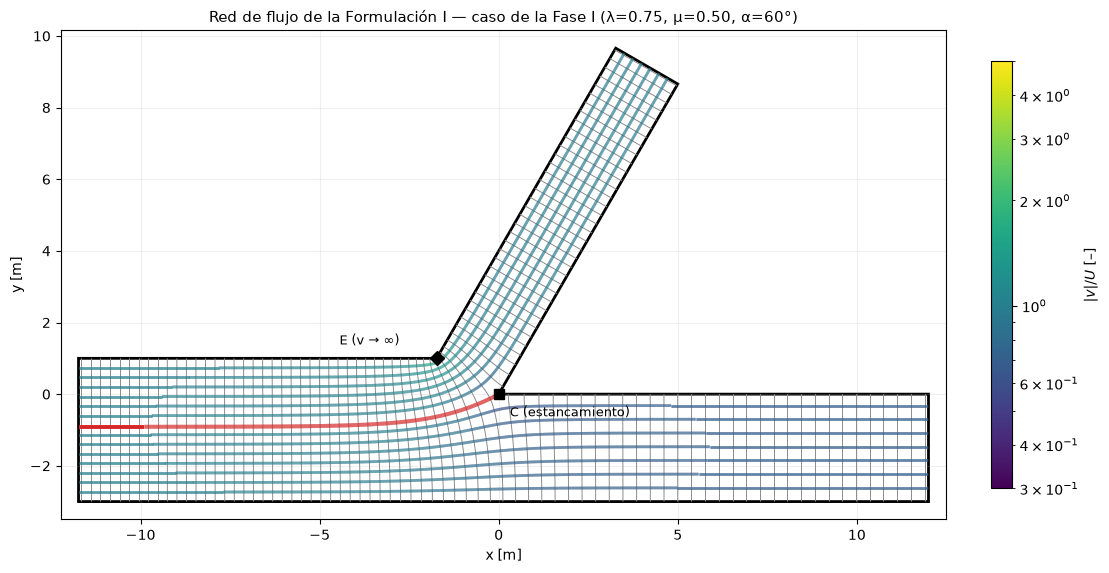

In [17]:
def dibujar(ax, nombre, R_, desplaza=0j, xlim=None, ylim=None, norma=LogNorm(0.3, 5), titulo=None, etiquetas=True):
    M, W, L, E_ = R_["M"], R_["W"], R_["L"], R_["E"]
    poly = W.poligono() + desplaza
    parche = Polygon(np.c_[poly.real, poly.imag], closed=True, fc="white", ec="k", lw=2, zorder=1)
    ax.add_patch(parche)
    for e_ in E_:
        z = e_["z"] + desplaza
        ln, = ax.plot(z.real, z.imag, "-", color="0.55", lw=0.7, zorder=2); ln.set_clip_path(parche)
    lc = None
    for l in L:
        z = l["z"] + desplaza; q = np.abs(M.vel(l["zeta"]))/M.U
        seg = np.c_[z.real, z.imag]; segs = np.stack([seg[:-1], seg[1:]], 1)
        if l["div"]:
            lc_d = LineCollection(segs, colors="tab:red", linewidths=2.8, zorder=4); ax.add_collection(lc_d); lc_d.set_clip_path(parche)
        else:
            lc = LineCollection(segs, array=0.5*(q[:-1] + q[1:]), cmap="viridis", norm=norma, linewidths=2.0, zorder=3)
            ax.add_collection(lc); lc.set_clip_path(parche)
    C = 0j + desplaza; Ept = complex(M.xE, M.ya) + desplaza
    ax.plot(C.real, C.imag, "s", color="k", ms=7, zorder=6); ax.plot(Ept.real, Ept.imag, "D", color="k", ms=7, zorder=6)
    if etiquetas:
        ax.annotate("C (estancamiento)", (C.real, C.imag), xytext=(8, -16), textcoords="offset points", fontsize=9, zorder=7)
        ax.annotate("E (v → ∞)", (Ept.real, Ept.imag), xytext=(-70, 10), textcoords="offset points", fontsize=9, zorder=7)
    ax.set_aspect("equal")
    p_ = poly
    ax.set_xlim(*(xlim or (p_.real.min() - 0.5, p_.real.max() + 0.5)))
    ax.set_ylim(*(ylim or (p_.imag.min() - 0.5, p_.imag.max() + 0.5)))
    ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
    ax.set_title(titulo or nombre, fontsize=11)
    ax.grid(True, alpha=0.2)
    return lc

fig, ax = plt.subplots(figsize=(11, 7.2), layout="constrained")
c = datos["casos"]["base_fase1"]
lc = dibujar(ax, "base_fase1", resultados["base_fase1"],
             titulo=f"Red de flujo de la Formulación I — caso de la Fase I (λ={c['h1']/c['h']:.2f}, μ={c['h2']/c['h']:.2f}, α={c['alpha_deg']:.0f}°)")
fig.colorbar(lc, ax=ax, shrink=0.6, label=r"$|v|/U$ [–]")
plt.show()

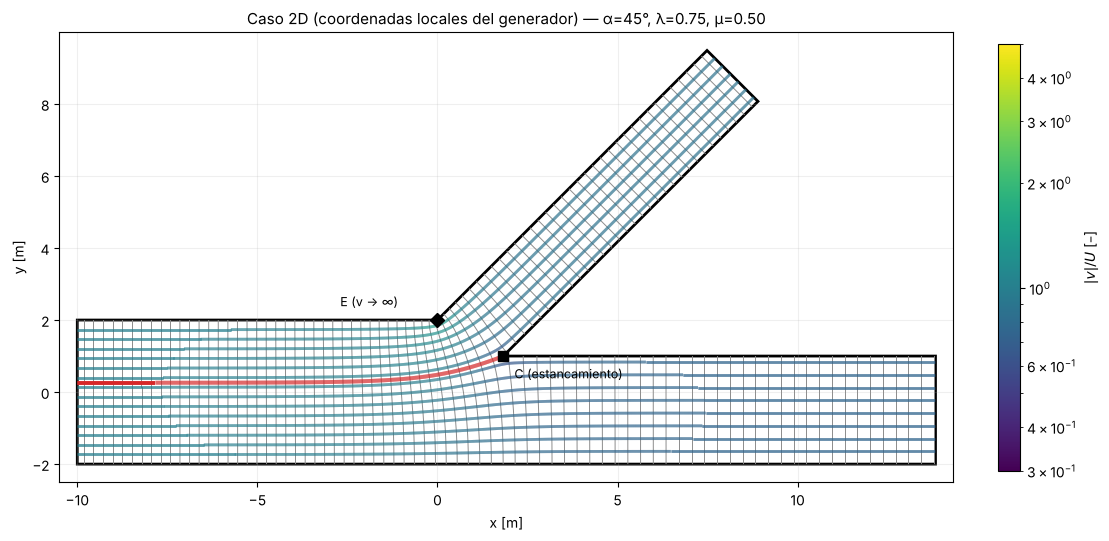

E = (0; 2.00) m  |  C = (1.8284; 1.0000) m  (coincide con el vértice C del generador 2D: x = 1.828, y = 1.000)


In [10]:
# Caso 2D, en las coordenadas locales del generador (E = (0; h/2)), para superponer con HEC-RAS
c2 = datos["casos"]["caso_2d"]; R2 = resultados["caso_2d"]; M2 = R2["M"]
desplaza_2d = -complex(M2.xE, M2.ya) + 1j*c2["h"]/2        # lleva E a (0, h/2); la pared lejana queda en y = -h/2
fig, ax = plt.subplots(figsize=(11, 7.2), layout="constrained")
lc = dibujar(ax, "caso_2d", R2, desplaza=desplaza_2d,
             titulo=f"Caso 2D (coordenadas locales del generador) — α={c2['alpha_deg']:.0f}°, λ={c2['h1']/c2['h']:.2f}, μ={c2['h2']/c2['h']:.2f}")
fig.colorbar(lc, ax=ax, shrink=0.6, label=r"$|v|/U$ [–]")
plt.show()
print(f"E = (0; {c2['h']/2:.2f}) m  |  C = ({(0j + desplaza_2d).real:.4f}; {(0j + desplaza_2d).imag:.4f}) m  "
      f"(coincide con el vértice C del generador 2D: x = 1.828, y = 1.000)")

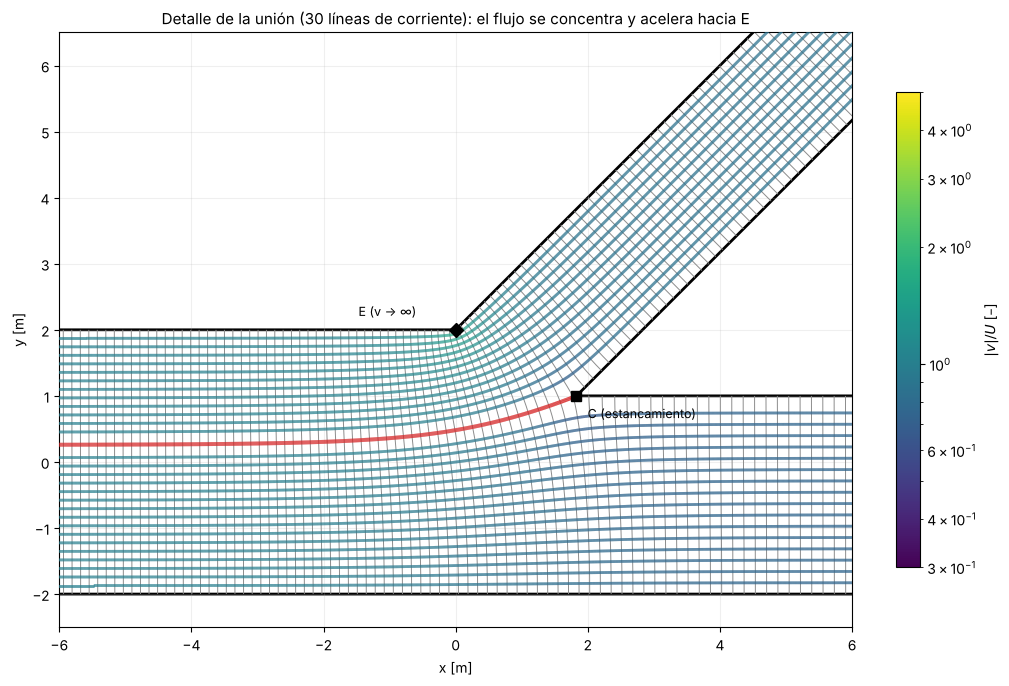

In [11]:
# Detalle de la unión con más líneas (caso 2D): se ve la concentración en E y el estancamiento en C
R2f = {}
M2 = resultados["caso_2d"]["M"]; W2 = resultados["caso_2d"]["W"]
L_f, E_f, d_f = trazar_lineas(M2, W2, n_psi=30)
R2f = dict(M=M2, W=W2, L=L_f, E=E_f)
fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")
lc = dibujar(ax, "detalle", R2f, desplaza=desplaza_2d, xlim=(-6, 6), ylim=(-2.5, 6.5), norma=LogNorm(0.3, 5),
             titulo="Detalle de la unión (30 líneas de corriente): el flujo se concentra y acelera hacia E")
fig.colorbar(lc, ax=ax, shrink=0.6, label=r"$|v|/U$ [–]")
plt.show()

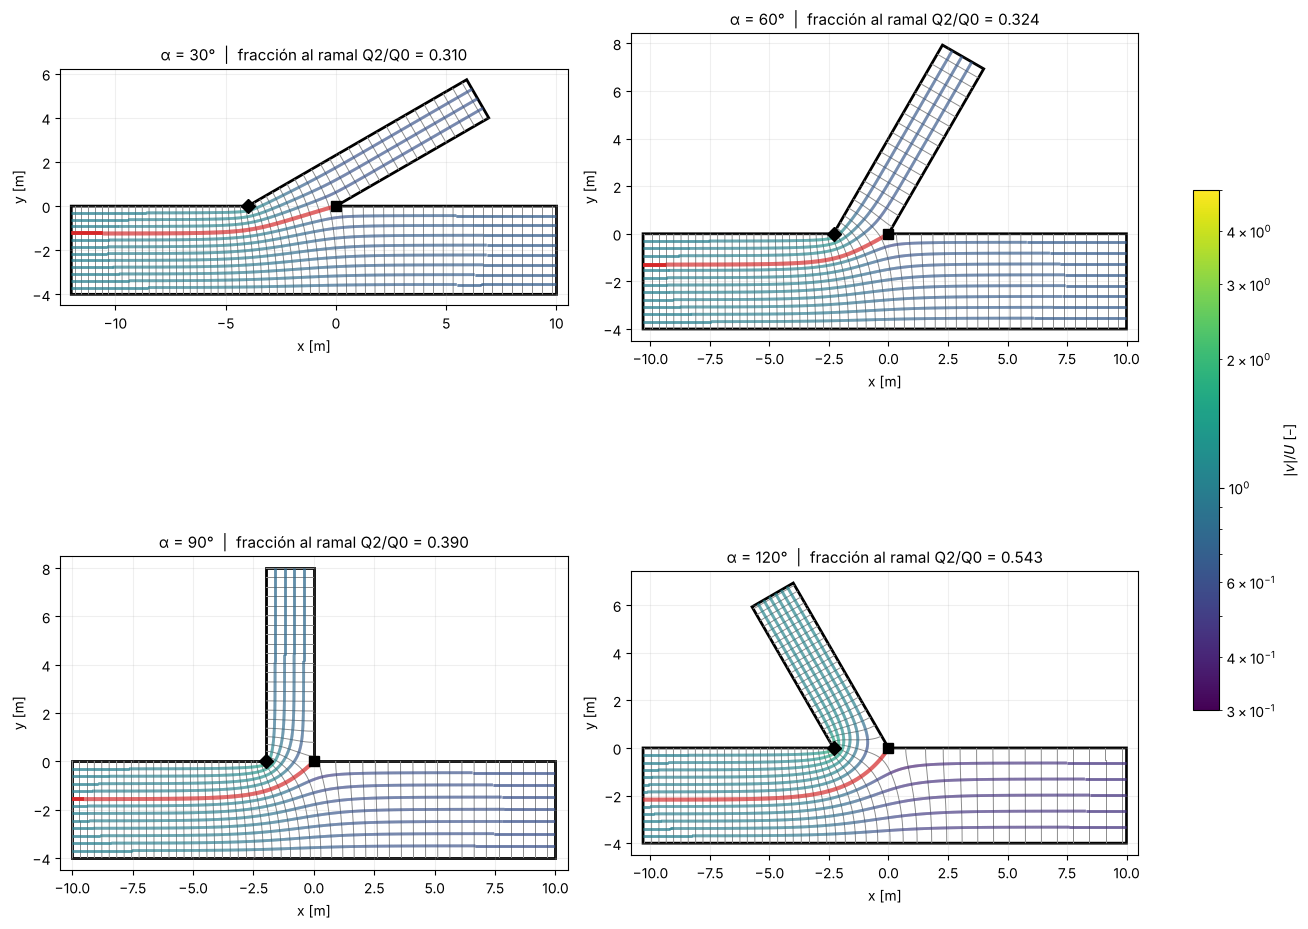

In [12]:
# Efecto del angulo (lambda = 1, mu = 0.5): mismas lineas, cuatro angulos
bar = datos["barrido"]
fig, axs = plt.subplots(2, 2, figsize=(13, 10.5), layout="constrained")
for ax, a_deg in zip(axs.ravel(), bar["alfa_deg"]):
    h = 4.0
    M = Mapa(h, bar["lambda"]*h, bar["mu"]*h, np.radians(a_deg), U=U0)
    W = Ventana(M, 8.0, 10.0, 8.0)
    L, E_, _ = trazar_lineas(M, W, n_psi=12)
    lc = dibujar(ax, "", dict(M=M, W=W, L=L, E=E_), titulo=f"α = {a_deg:.0f}°  |  fracción al ramal Q2/Q0 = {M.Q2/M.Q0:.3f}",
                 etiquetas=False, norma=LogNorm(0.3, 5))
fig.colorbar(lc, ax=axs, shrink=0.5, label=r"$|v|/U$ [–]")
plt.show()

## 10. Velocidades características (modelo ideal)

El modelo da velocidades **uniformes y conocidas** lejos de la unión, y una velocidad que crece sin límite hacia $E$. La tabla muestra qué tan cerca de $E$ está el valor máximo que alcanza una línea de corriente dentro de la ventana de dibujo (depende de cuánto se acerque esa línea), y la velocidad de las zonas uniformes.

In [13]:
filas = []
for nombre, R_ in resultados.items():
    M, L = R_["M"], R_["L"]
    qmax = max((np.abs(M.vel(l["zeta"]))/M.U)[~R_["W"].fuera(l["z"])].max() for l in L if not l["div"])
    filas.append({"Caso": nombre, "U [m/s] (aguas arriba)": M.U, "U1 [m/s] (canal principal)": M.u1*M.U,
                  "U2 [m/s] (ramal)": M.u2*M.U, "|v|máx / U en las líneas trazadas": qmax,
                  "Exponente de la singularidad en E": -M.alpha/(np.pi + M.alpha)})
display(pd.DataFrame(filas).style.format({"U [m/s] (aguas arriba)": "{:.4f}", "U1 [m/s] (canal principal)": "{:.4f}",
        "U2 [m/s] (ramal)": "{:.4f}", "|v|máx / U en las líneas trazadas": "{:.2f}",
        "Exponente de la singularidad en E": "{:.4f}"}).hide(axis="index"))

Caso,U [m/s] (aguas arriba),U1 [m/s] (canal principal),U2 [m/s] (ramal),|v|máx / U en las líneas trazadas,Exponente de la singularidad en E
base_fase1,1.0000,0.6758,0.6484,1.62,-0.2500
caso_2d,1.0000,0.7529,0.8707,1.50,-0.2000


## 11. Exportación para superponer en HEC-RAS / QGIS (caso 2D)

Se guardan las líneas del caso 2D, recortadas a la ventana, en el sistema local del generador y en UTM 18 S ficticias (mismo origen que el generador: $X=500000$, $Y=8500000$, EPSG:32718). Las equipotenciales y las líneas de corriente se guardan como polilíneas separadas por `id`, adelgazadas (1 de cada 6 o 4 puntos) para que el archivo sea liviano; la resolución sigue siendo de sobra para dibujar. Si está instalado `pyshp`, también se escribe un shapefile.

In [14]:
org = datos["origen_utm_ficticio"]
filas = []
for k, l in enumerate(R2["L"]):
    z = l["z"] + desplaza_2d; ok = ~R2["W"].fuera(l["z"])
    for zz, qq in zip(z[ok][::6], (np.abs(M2.vel(l["zeta"]))/M2.U)[ok][::6]):
        filas.append(("divisoria" if l["div"] else "corriente", f"psi_{k:02d}", l["psi"], zz.real, zz.imag, zz.real + org["X"], zz.imag + org["Y"], qq))
for k, e_ in enumerate(R2["E"]):
    z = e_["z"] + desplaza_2d; ok = ~R2["W"].fuera(e_["z"])
    for zz in z[ok][::4]:
        filas.append(("equipotencial", f"phi_{k:03d}_{e_['tipo']}", e_["phi"], zz.real, zz.imag, zz.real + org["X"], zz.imag + org["Y"], np.nan))
df_exp = pd.DataFrame(filas, columns=["familia", "id", "valor_psi_o_phi", "x_local_m", "y_local_m", "x_utm_m", "y_utm_m", "v_sobre_U"])
df_exp.to_csv("lineas_corriente_caso2d.csv", index=False)
print("lineas_corriente_caso2d.csv:", len(df_exp), "puntos;", df_exp["id"].nunique(), "polilíneas")
display(df_exp.groupby("familia")["id"].nunique().rename("n polilíneas").to_frame())

try:
    import shapefile
    w = shapefile.Writer("lineas_corriente_caso2d", shapeType=shapefile.POLYLINE)
    w.field("familia", "C", 14); w.field("id", "C", 24); w.field("valor", "F", 14, 6)
    for (fam, idv), g in df_exp.groupby(["familia", "id"], sort=False):
        w.line([g[["x_utm_m", "y_utm_m"]].to_numpy().tolist()]); w.record(fam, idv, float(g["valor_psi_o_phi"].iloc[0]))
    w.close()
    open("lineas_corriente_caso2d.prj", "w").write(
        'PROJCS["WGS_1984_UTM_Zone_18S",GEOGCS["GCS_WGS_1984",DATUM["D_WGS_1984",SPHEROID["WGS_1984",6378137.0,298.257223563]],'
        'PRIMEM["Greenwich",0.0],UNIT["Degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],'
        'PARAMETER["False_Easting",500000.0],PARAMETER["False_Northing",10000000.0],PARAMETER["Central_Meridian",-75.0],'
        'PARAMETER["Scale_Factor",0.9996],PARAMETER["Latitude_Of_Origin",0.0],UNIT["Meter",1.0]]')
    print("Shapefile escrito: lineas_corriente_caso2d.shp")
except ImportError:
    print("pyshp no está instalado: solo se escribió el CSV (pip install pyshp para generar el shapefile).")

lineas_corriente_caso2d.csv: 29050 puntos; 124 polilíneas


,n polilíneas
familia,
corriente,14
divisoria,1
equipotencial,109


Shapefile escrito: lineas_corriente_caso2d.shp


## 12. Lectura de los resultados y qué hacer con ellos

**Lo que muestra la red de flujo**

1. **Aguas arriba** el flujo es uniforme ($|v|=U$); **aguas abajo** lo es de nuevo, con $U_1$ en el canal principal y $U_2$ en el ramal. La unión solo perturba una zona de unas pocas anchuras de canal.
2. **La divisoria** $\psi=-Q_2$ sale del flujo aguas arriba y termina en $C$: lo que queda por encima de ella entra al ramal. La fracción $Q_2/Q_0$ es exactamente la distancia entre la divisoria y la pared, en unidades de $\psi$.
3. **Cerca de $E$**, las líneas de corriente se aprietan y la velocidad crece sin límite ($q\sim r^{-\alpha/(\pi+\alpha)}$, exponente entre $-0.14$ y $-0.4$ para $\alpha$ entre 30° y 120°). Es la señal de que el flujo ideal **no puede ser el real** ahí: la presión mínima en $E$ y el gradiente adverso aguas abajo favorecen la **separación**.
4. **Con el ángulo**, la zona de aceleración en $E$ se vuelve más marcada a medida que $\alpha$ crece (el fluido gira más), y el estancamiento en $C$ siempre está presente.

**Qué hipótesis dejan planteada (para contrastar en la Fase IV, no demostradas aquí)**

- En el flujo real, aguas abajo de $E$ aparece una **zona de separación** pegada a la pared del ramal. Su efecto sería **estrechar el ancho efectivo del ramal**, y eso reduciría la fracción que toma frente a la predicha por el modelo ideal. Es coherente con lo observado en la Fase I (el ideal sobrestima a 90° frente a la LES publicada), pero **no es una conclusión**: se contrasta con los campos de velocidad del 2D.
- **Superposición con HEC-RAS.** El archivo `lineas_corriente_caso2d.csv` (o el shapefile) se puede cargar sobre el resultado del 2D. En RAS Mapper, las trayectorias de partículas (*particle tracing*) o los vectores de velocidad permiten comparar visualmente la divisoria y la zona cercana a $E$ con esta figura.
- **Medida cuantitativa sugerida:** la posición donde la divisoria ideal toca la pared aguas arriba (a qué distancia de $E$ termina el flujo que entra al ramal) frente a la del 2D, además de la fracción $Q_2/Q_0$.

**Limitaciones**

- Modelo plano y sin fricción: no depende de $Fr$, de la profundidad, del control aguas abajo ni de la rugosidad.
- La red de flujo es la del modelo ideal, no una simulación. Cerca de $E$ la velocidad es infinita y las líneas tienen resolución finita.
- Datos hipotéticos.

**Siguiente paso posible (opcional, a decidir tras ver estas gráficas):** la corrección por separación con la teoría de chorros libres (Gurevich, §10; Batchelor, §6.13), que cambiaría la condición en $E$.

## 13. Referencias de esta fase (verificar volumen, páginas y DOI antes de incluirlas en el informe)

- Milne-Thomson, L. M. *Theoretical Hydrodynamics*, §10·8, «Branch in a canal».
- Batchelor, G. K. (2000). *An Introduction to Fluid Dynamics* (Cambridge Mathematical Library). Cambridge University Press. §6.5 (potencial complejo y transformación conforme) y §6.13 (teoría de líneas de corriente libres).
- Gurevich, M. I. (1966). *The Theory of Jets in an Ideal Fluid*. Pergamon Press. Cap. I, §1; §10.
- Birkhoff, G. y Zarantonello, E. H. (1957). *Jets, Wakes, and Cavities*. Academic Press.